# Interpretability: What Are the Drum Models Actually Looking At?

**P2 Notebook 4**

Notebook 3 gave us three trained models and a test accuracy for each. Accuracy says how often a model is right, not **why**. On a dataset we scraped ourselves, "why" matters: a model can score well by reading a watermark, a studio background or the gray padding bars we added, and fail the moment it meets a drum photographed somewhere else. Here we open the three models up with saliency maps and Grad-CAM, and hunt for exactly that kind of shortcut.

We do not train anything in this notebook. The probes are loaded from `models/`, and the maps come from the provided `image_explainers.py`, which we read before using (section 0).

## Learning objectives

- Join a Keras application and its trained probe into the single model that `image_explainers` accepts
- Produce raw saliency, SmoothGrad and Grad-CAM maps, and say what each one can and cannot show
- Explain correct predictions, mistakes, and the **same image across three applications**
- Look for shortcuts (padding, borders, background, image source) and **measure** them with ablations, not just look at pictures
- Judge whether the models are fit to deploy, and what to fix first

## Background

A **saliency map** is the gradient of a class score with respect to the image's pixels: it marks the pixels that would change the score fastest if nudged. It is pixel-precise but speckled. **SmoothGrad** averages that gradient over noisy copies of the image, which cancels the speckle and keeps what the model responds to consistently. **Grad-CAM** asks instead which channels of the application's last feature maps support the class, and paints their weighted sum back onto the image: coarse (the feature maps are small), but it shows *where* the evidence sits.

A map is a **hypothesis**, not a measurement. It suggests what the model uses; only an ablation, where we remove a region and re-measure accuracy, shows whether the model really depends on it.

## This notebook covers

0. What `image_explainers.py` does
1. Setup: the test set, the three joined models, and a check that the join is right
2. Both methods running: raw saliency, SmoothGrad and Grad-CAM
3. Where to point them: correct predictions, mistakes, and one image across all three applications
4. The shortcut hunt: padding, borders, per-class attention, image source and ablations
5. Do the methods agree?
6. Discussion

**Prerequisites:** Notebook 2 (test set, label-to-index mapping, split table, manifest) and Notebook 3 (the probes in `models/`). `image_explainers.py` sits beside this notebook.

**Dataset:** our cleaned drum test images, exactly as Notebook 2 saved them: padded to square, 224 × 224, raw 0–255 pixels. The training images are read in one place only, to draw the per-class mean images.

**Produces:** nothing on disk. Everything here is read-only analysis.

**References:** `U2-2_CNN-6_TransferLearning` §5, `U2-2_CNN-8_Explainability` §3–4, `U2-2_CNN-9_FairnessAudit` §8, and the provided `image_explainers_demo.ipynb`.

**Running it:** the maps and ablations run the three models over the whole test set several times, so expect roughly 30 to 60 minutes on a laptop CPU, most of it spent on `EfficientNetV2M`: section 4.2 (Grad-CAM for every test image) and section 5 (SmoothGrad on 24 images) are the slow parts. Everything is seeded, so a re-run gives the same pictures.

In [1]:
import json
import time
from pathlib import Path
from urllib.parse import urlparse

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from sklearn.metrics import accuracy_score, f1_score
from sklearn.tree import DecisionTreeClassifier

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)

plt.style.use('dark_background')

import warnings
warnings.filterwarnings('ignore')

import image_explainers as xai      # the provided module, copied beside this notebook and not modified

SEED = 42
keras.utils.set_random_seed(SEED)

IMG_SIZE = 224
WEIGHTS = 'imagenet'      # the weights every application is loaded with, as in Notebook 3
SMOOTH = 32               # noisy copies averaged by SmoothGrad
BAND = 28                 # width in pixels of the border band used in section 4 (an eighth of the image)
ABLATE_FRAC = 0.20        # share of the image removed in the Grad-CAM ablation

PROC_DIR = Path.home() / 'MSDS565_data' / 'P2_processed'      # Notebook 2's output, outside the repo
MODELS_DIR = Path('..') / 'models'                            # Notebook 3's probes
MANIFEST_PATH = Path('..') / 'data' / 'P2_manifest.csv'

## 0. What `image_explainers.py` does

We read the module before using it. Four things in it decide whether our maps can be trusted:

1. **It applies each application's own `preprocess_input`**, found from the application's Keras name. So we hand it the raw 0–255 image exactly as Notebook 2 saved it, and it refuses an image that already looks scaled, which would be preprocessed twice.
2. **It reads the class score before the softmax** (`x @ W + b` of the probe's last `Dense` layer). A confident softmax is flat, so its gradient is close to zero and the maps would be noise. This only works because our probe's last layer is that `Dense`.
3. **Grad-CAM takes the application's last 4-dimensional layer**, the stack of feature maps just before `pooling='avg'` averages them into the embedding vector, and upsamples the result bilinearly to the image size.
4. **SmoothGrad adds Gaussian noise of 10% of the pixel range** to `smooth` copies of the image. The noise comes from `numpy`'s random generator, so we seed it before every call to make the maps repeatable.

Every explainer explains one class's score: the predicted class by default, or any class we name with `class_index`.

## 1. Setup

### 1.1 Load the test set

Everything comes from Notebook 2's output folder: the test images, their labels, the label-to-index mapping, and the split table that says which file each test image came from. The training arrays are loaded only to draw per-class mean images in section 4.3. The manifest gives the web page each image came from, which section 4.6 uses.

In [2]:
X_train = np.load(PROC_DIR / 'X_train.npy')
y_train = np.load(PROC_DIR / 'y_train.npy')
X_test = np.load(PROC_DIR / 'X_test.npy')
y_test = np.load(PROC_DIR / 'y_test.npy')

label_to_index = json.loads((PROC_DIR / 'label_to_index.json').read_text())
class_names = [name for name, i in sorted(label_to_index.items(), key=lambda kv: kv[1])]
n_classes = len(class_names)

prep = json.loads((PROC_DIR / 'preprocessing.json').read_text())
PAD_FILL = prep['pad_color'][0]
assert prep['img_size'] == IMG_SIZE and X_test.shape[1:] == (IMG_SIZE, IMG_SIZE, 3) and X_test.dtype == np.uint8

# Which file and web page every row of the arrays came from
split = pd.read_csv(PROC_DIR / 'split.csv')
manifest = pd.read_csv(MANIFEST_PATH)
manifest_cols = manifest[['label', 'filename', 'source_url']]


def clean_domain(url):
    if not isinstance(url, str):
        return 'unknown'
    host = urlparse(url).netloc.lower()
    return host[4:] if host.startswith('www.') else (host or 'unknown')


def rows_of(which):
    rows = split[split['split'] == which].sort_values('position').merge(manifest_cols, on=['label', 'filename'], how='left')
    rows['domain'] = rows['source_url'].map(clean_domain)
    return rows.reset_index(drop=True)


test_rows, train_rows = rows_of('test'), rows_of('train')
assert len(test_rows) == len(X_test) and len(train_rows) == len(X_train)
assert (test_rows['label'].map(label_to_index).to_numpy() == y_test).all(), 'split.csv and the test arrays disagree'

print(f'test {X_test.shape}, {n_classes} classes, pad fill {PAD_FILL}')
pd.DataFrame({'test images': np.bincount(y_test, minlength=n_classes)}, index=class_names).T

test (420, 224, 224, 3), 8 classes, pad fill 114


,ashiko,bata,bendir,bougarabou,djembe,dunun,sabar,talking_drum
test images,56,43,53,47,61,57,60,43


### 1.2 Rebuild each application and join it to its probe

Each application is rebuilt with exactly the call Notebook 3 used (`include_top=False, pooling='avg'`, the same `imagenet` weights), the probe is loaded from `models/`, and the two are joined with `keras.Sequential([keras.Input(...), keras_app, probe])`. The filename of each probe, `P2_N3_<application>.keras`, is how we know which application it belongs to.

The last column is the **natural Grad-CAM resolution** of each application: the height and width of its last feature maps, which is as fine as a Grad-CAM map can ever be before it is stretched to 224 × 224.

In [3]:
APPLICATIONS = {
    'mobilenetv2': dict(name='MobileNetV2', tier='small',
        build=lambda: keras.applications.MobileNetV2(weights=WEIGHTS, include_top=False, pooling='avg', input_shape=(IMG_SIZE, IMG_SIZE, 3))),
    'resnet50': dict(name='ResNet50', tier='medium',
        build=lambda: keras.applications.ResNet50(weights=WEIGHTS, include_top=False, pooling='avg', input_shape=(IMG_SIZE, IMG_SIZE, 3))),
    'effnetv2m': dict(name='EfficientNetV2M', tier='large',
        build=lambda: keras.applications.EfficientNetV2M(weights=WEIGHTS, include_top=False, pooling='avg', input_shape=(IMG_SIZE, IMG_SIZE, 3))),
}
NAME = {key: cfg['name'] for key, cfg in APPLICATIONS.items()}

keras_apps, joined, rows = {}, {}, []
for key, cfg in APPLICATIONS.items():
    keras_app = cfg['build']()
    keras_app.trainable = False
    probe = keras.models.load_model(MODELS_DIR / f'P2_N3_{key}.keras')
    keras_apps[key] = keras_app
    joined[key] = keras.Sequential([keras.Input((IMG_SIZE, IMG_SIZE, 3)), keras_app, probe])

    last_maps = [layer for layer in keras_app.layers if len(layer.output.shape) == 4][-1]
    _, h, w, channels = last_maps.output.shape
    rows.append({'application': cfg['name'], 'Keras name': keras_app.name, 'parameters (M)': round(keras_app.count_params() / 1e6, 1),
                 'embedding length': int(keras_app.output.shape[-1]), 'last feature maps': f'{h} x {w} x {channels}',
                 'natural Grad-CAM grid': f'{h} x {w}'})
pd.DataFrame(rows).set_index('application')

,Keras name,parameters (M),embedding length,last feature maps,natural Grad-CAM grid
application,,,,,
MobileNetV2,mobilenetv2_1.00_224,2.3,1280,7 x 7 x 1280,7 x 7
ResNet50,resnet50,23.6,2048,7 x 7 x 2048,7 x 7
EfficientNetV2M,efficientnetv2-m,53.2,1280,7 x 7 x 1280,7 x 7


### 1.3 Check the join before trusting any map

If a model were joined wrongly, every map below would be a confident explanation of the wrong thing. So we first predict the whole test set with each joined model and confirm two things: the accuracy and macro-F1 match **Notebook 3's table**, and the module's `predict_proba` on a raw image agrees with a plain `model.predict` on the preprocessed image.

The helper applies the application's own `preprocess_input` to a float **copy** (it changes numpy arrays in place) and then calls the joined model. Later sections reuse it for the ablations.

In [4]:
def predict_probs(key, images, batch=64):
    pre = xai.find_preprocess_input(keras_apps[key])
    out = [joined[key].predict(pre(images[s:s + batch].astype('float32')), verbose=0) for s in range(0, len(images), batch)]
    return np.concatenate(out)


probs = {key: predict_probs(key, X_test) for key in APPLICATIONS}
pred = {key: p.argmax(axis=1) for key, p in probs.items()}

check = pd.DataFrame({NAME[key]: {'test accuracy': accuracy_score(y_test, pred[key]),
                                  'macro-F1': f1_score(y_test, pred[key], average='macro'),
                                  'misclassified': int((pred[key] != y_test).sum())} for key in APPLICATIONS}).T

# The module's own route (raw image in) must agree with the plain Keras route (preprocessed image in)
for key in APPLICATIONS:
    for i in (0, len(X_test) // 2, len(X_test) - 1):
        assert np.abs(xai.predict_proba(joined[key], X_test[i]) - probs[key][i]).max() < 1e-3, (key, i)

PRIMARY = max(APPLICATIONS, key=lambda k: accuracy_score(y_test, pred[k]))      # the most accurate model, used for the single-model figures
print(f'The module and plain Keras agree on every image checked. Single-model figures use {NAME[PRIMARY]}, the most accurate.')
check.round(3)

The module and plain Keras agree on every image checked. Single-model figures use ResNet50, the most accurate.


,test accuracy,macro-F1,misclassified
MobileNetV2,0.76,0.755,101.0
ResNet50,0.79,0.785,88.0
EfficientNetV2M,0.76,0.755,101.0


## 2. Both methods running

One image, all three maps. `get_maps` computes and remembers the raw saliency map, the SmoothGrad map (32 noisy copies) and the Grad-CAM map for the model's predicted class, seeding the noise from the image's index so the map is the same whenever it is drawn. Every later section reuses it.

`roughness` puts a number on "speckled": the average difference between neighboring pixels of the normalized map, relative to its average brightness. A smooth blob scores low, salt-and-pepper scores high.

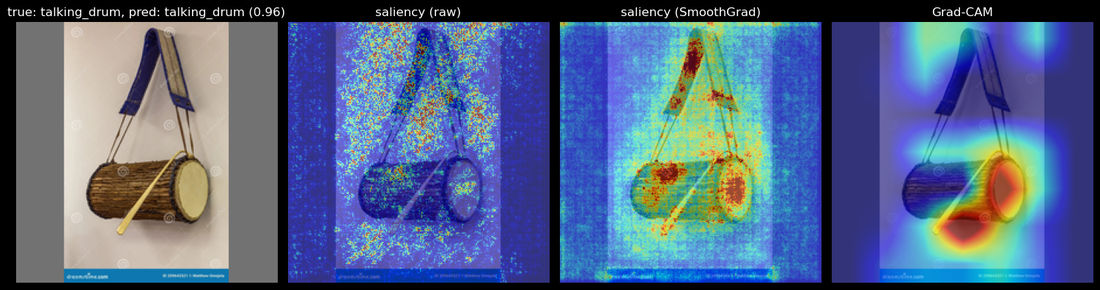

ResNet50 on test image 0: maps are (224, 224); roughness raw 1.14, SmoothGrad 0.31, Grad-CAM 0.06


In [5]:
_maps_cache = {}


def get_maps(key, idx):
    if (key, idx) not in _maps_cache:
        model, img = joined[key], X_test[idx]
        probs_i = xai.predict_proba(model, img)
        p = int(probs_i.argmax())
        np.random.seed(SEED + int(idx))
        _maps_cache[(key, idx)] = dict(
            probs=probs_i, pred=p,
            raw=xai.saliency(model, img, class_index=p),
            smooth=xai.saliency(model, img, smooth=SMOOTH, class_index=p),
            cam=xai.grad_cam(model, img, class_index=p))
    return _maps_cache[(key, idx)]


def roughness(heat):
    h = xai.norm(heat)
    return (np.abs(np.diff(h, axis=0)).mean() + np.abs(np.diff(h, axis=1)).mean()) / (h.mean() + 1e-8)


demo_idx = int(np.where(pred[PRIMARY] == y_test)[0][0])        # the first test image the primary model gets right
m = get_maps(PRIMARY, demo_idx)

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
axes[0].imshow(X_test[demo_idx])
axes[0].set_title(f'true: {class_names[y_test[demo_idx]]}, pred: {class_names[m["pred"]]} ({m["probs"][m["pred"]]:.2f})')
for ax, (title, heat) in zip(axes[1:], [('saliency (raw)', m['raw']), ('saliency (SmoothGrad)', m['smooth']), ('Grad-CAM', m['cam'])]):
    ax.imshow(xai.overlay(X_test[demo_idx], heat))
    ax.set_title(title)
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

print(f"{NAME[PRIMARY]} on test image {demo_idx}: maps are {m['raw'].shape}; roughness raw {roughness(m['raw']):.2f}, SmoothGrad {roughness(m['smooth']):.2f}, Grad-CAM {roughness(m['cam']):.2f}")

### 2.1 Raw saliency against SmoothGrad

Both maps come from the same gradient; SmoothGrad just averages it over 32 noisy copies. The raw map is **pixel-precise but speckled**, because one gradient is a noisy local measurement and a single pixel can swing it. Averaging cancels the noise that points in random directions and keeps what the model responds to consistently, so SmoothGrad draws the **shape** the model uses (the edge of a drum body, a rim, a pattern of cords) instead of scattered dots. The roughness numbers above give the same comparison; section 5 repeats it over 24 images.

The price of SmoothGrad is time (32 backward passes instead of one) and a little blur: it can no longer say which exact pixel mattered.

### 2.2 Grad-CAM and its resolution

The table in section 1.2 gives the natural Grad-CAM grid of each application. At 224 × 224 input, all three end in a **7 × 7** grid, so one Grad-CAM cell covers a 32 × 32 pixel square of the image. The smooth blob in the picture is that 7 × 7 grid stretched bilinearly, not real detail. Grad-CAM can say "the evidence is in the upper left", but not "it is this particular pixel", and a thin object such as a watermark can be smeared into its neighbors.

*TEAM TO COMPLETE AFTER RUNNING — replace this cell with 2–3 sentences in your own words on this image: how do the three maps differ, and do they highlight the drum?*

## 3. Where to point them

### 3.1 Choosing the images

Choosing images by eye invites choosing the flattering ones, so the selection is a seeded random draw, and the rule is stated here:

- **Three correct images**, drawn from three different classes, among the test images that **all three applications** classify correctly. That lets section 3.4 compare the applications on an image they all get right.
- **Three misclassified images**, drawn from three different true classes, among the images the primary model gets wrong. These are the informative ones.

To look at specific images instead, overwrite `CORRECT_IDX` and `WRONG_IDX` with test-set indices.

In [6]:
rng = np.random.default_rng(SEED)

all_right = np.where(np.all([pred[k] == y_test for k in APPLICATIONS], axis=0))[0]
right_classes = sorted(set(y_test[all_right]))
assert len(right_classes) >= 3, 'need images that all three applications get right, from at least three classes'
CORRECT_IDX = [int(rng.choice(all_right[y_test[all_right] == c])) for c in rng.choice(right_classes, size=3, replace=False)]

wrong = np.where(pred[PRIMARY] != y_test)[0]
wrong_classes = sorted(set(y_test[wrong]))
WRONG_IDX = [int(rng.choice(wrong[y_test[wrong] == c])) for c in rng.choice(wrong_classes, size=min(3, len(wrong_classes)), replace=False)]
while len(WRONG_IDX) < 3:                                       # fewer than three classes with mistakes: fill from the rest
    WRONG_IDX.append(int(rng.choice([i for i in wrong if i not in WRONG_IDX])))

chosen = pd.DataFrame({
    'kind': ['correct'] * 3 + ['misclassified'] * 3,
    'test index': CORRECT_IDX + WRONG_IDX,
    'file': [test_rows.loc[i, 'filename'] for i in CORRECT_IDX + WRONG_IDX],
    'true class': [class_names[y_test[i]] for i in CORRECT_IDX + WRONG_IDX],
    **{f'{NAME[k]} says': [class_names[pred[k][i]] for i in CORRECT_IDX + WRONG_IDX] for k in APPLICATIONS},
    'source': [test_rows.loc[i, 'domain'] for i in CORRECT_IDX + WRONG_IDX],
})
chosen

,kind,test index,file,true class,MobileNetV2 says,ResNet50 says,EfficientNetV2M says,source
0,correct,308,talking_drum_0138.jpg,talking_drum,talking_drum,talking_drum,talking_drum,africanmuseum.ie
1,correct,34,ashiko_0007.jpg,ashiko,ashiko,ashiko,ashiko,storage.googleapis.com
2,correct,306,dunun_0206.jpg,dunun,dunun,dunun,dunun,african-percussion.net
3,misclassified,347,bata_0195.jpg,bata,talking_drum,talking_drum,bata,valterpercussion.com
4,misclassified,384,ashiko_0307.jpg,ashiko,bougarabou,dunun,bougarabou,soundmystery.com
5,misclassified,342,djembe_0320.jpg,djembe,sabar,sabar,bougarabou,pinterest.com


### 3.2 Three correctly classified images

`xai.explain` draws the image beside all three maps for the predicted class, titled with the true and predicted class and the model's confidence. Primary model only here; section 3.4 compares the applications.

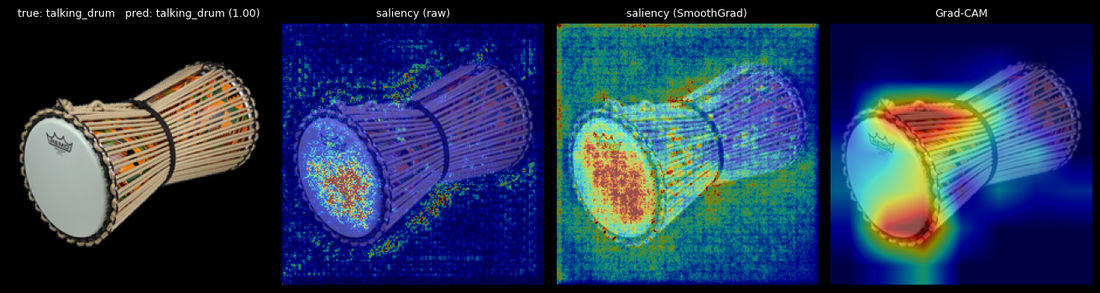

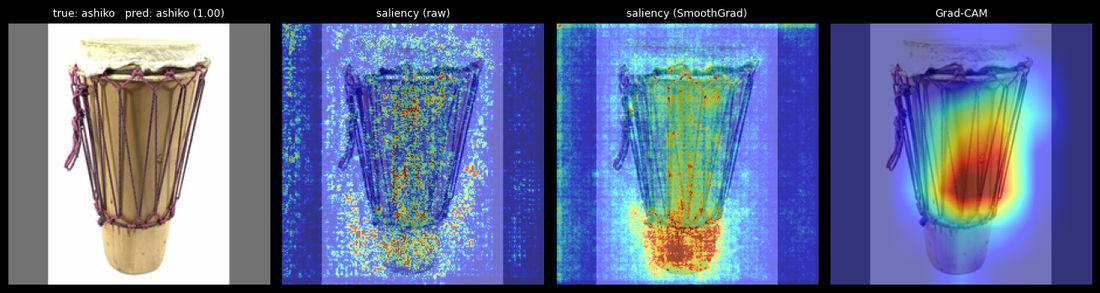

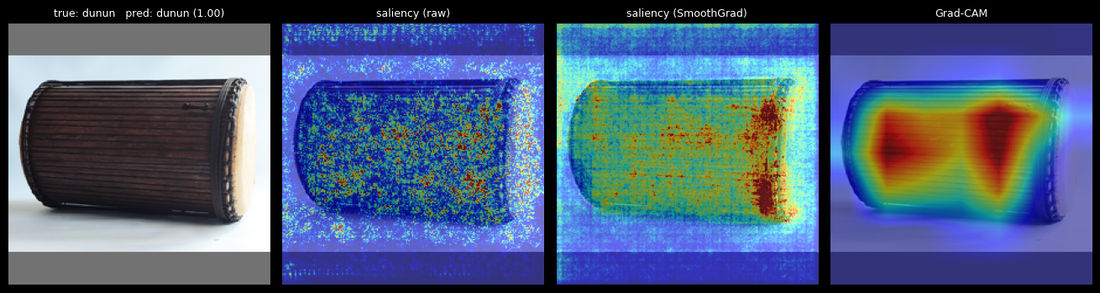

In [7]:
for i in CORRECT_IDX:
    np.random.seed(SEED + i)
    xai.explain(joined[PRIMARY], X_test[i], class_names, true_label=y_test[i], smooth=SMOOTH)

*TEAM TO COMPLETE AFTER RUNNING — replace this cell with 3–4 sentences.* For each of the three correct images: does the heat sit on the drum (its body, skin, rim, shape) or on something else (a hand, the floor, a wall, text, the gray padding)? Are the three classes explained in the same way, or does one rely on something the others do not? Being right for the wrong reason counts as a finding.

### 3.3 Three misclassified images

Same picture, then one more question. Every explainer explains the predicted class by default, which on a mistake shows what convinced the model of the **wrong** answer. Passing `class_index` asks what evidence it saw for the **true** class, so we can tell "looked at the wrong thing" from "looked at the right thing and read it wrongly".

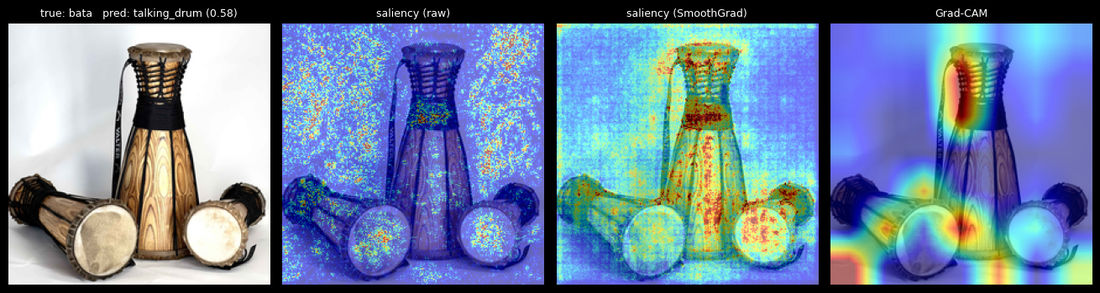

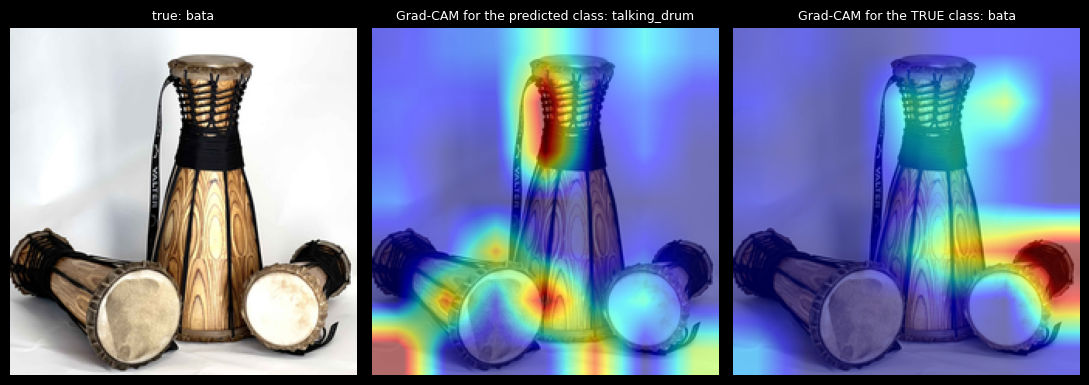

top 3 probabilities: talking_drum 0.58, bata 0.41, djembe 0.01 | true class bata: 0.41



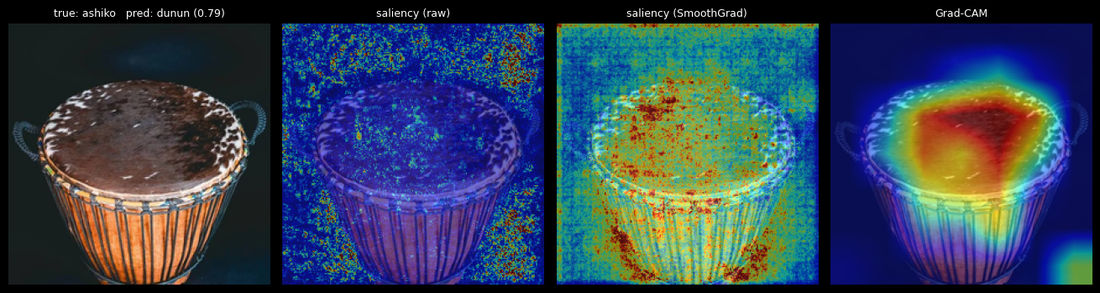

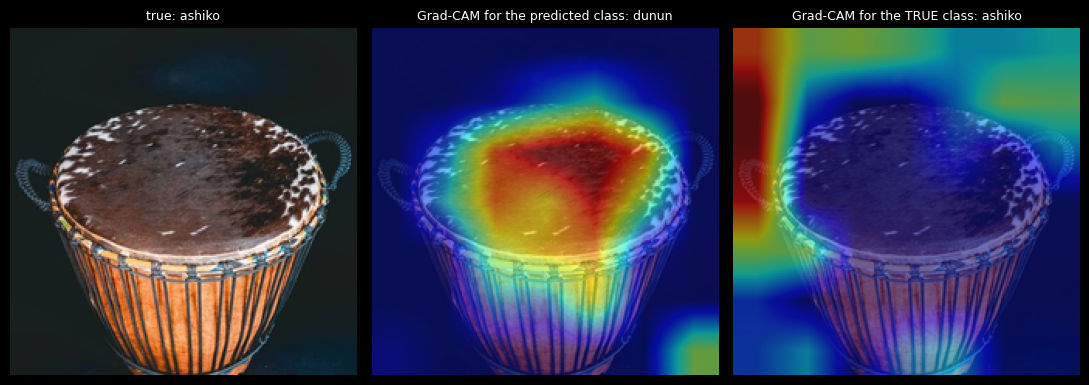

top 3 probabilities: dunun 0.79, ashiko 0.14, bougarabou 0.07 | true class ashiko: 0.14



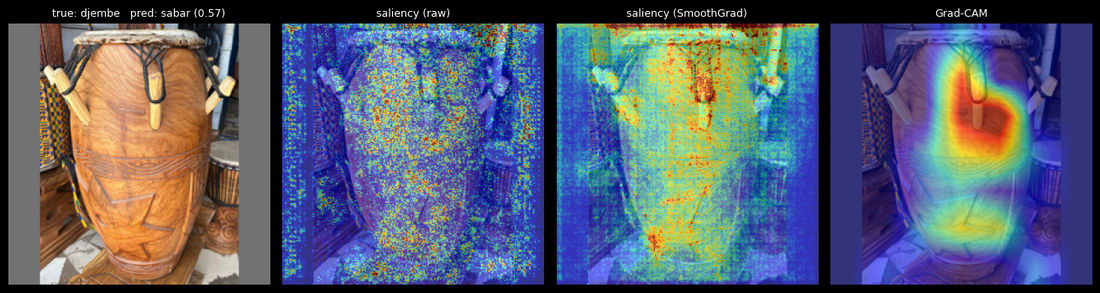

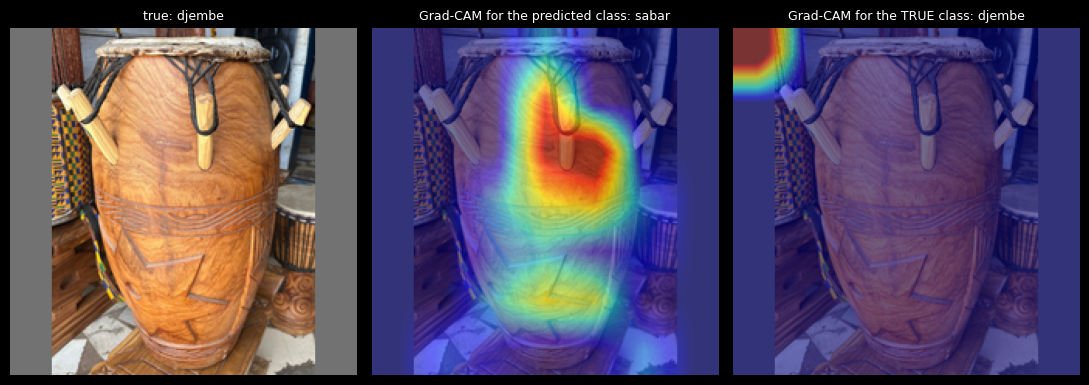

top 3 probabilities: sabar 0.57, ashiko 0.36, dunun 0.07 | true class djembe: 0.00



In [8]:
model = joined[PRIMARY]
for i in WRONG_IDX:
    np.random.seed(SEED + i)
    xai.explain(model, X_test[i], class_names, true_label=y_test[i], smooth=SMOOTH)

    p, t = int(pred[PRIMARY][i]), int(y_test[i])
    cam_pred = xai.grad_cam(model, X_test[i])
    cam_true = xai.grad_cam(model, X_test[i], class_index=t)
    top3 = np.argsort(probs[PRIMARY][i])[::-1][:3]

    fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
    axes[0].imshow(X_test[i]); axes[0].set_title(f'true: {class_names[t]}', fontsize=9)
    axes[1].imshow(xai.overlay(X_test[i], cam_pred)); axes[1].set_title(f'Grad-CAM for the predicted class: {class_names[p]}', fontsize=9)
    axes[2].imshow(xai.overlay(X_test[i], cam_true)); axes[2].set_title(f'Grad-CAM for the TRUE class: {class_names[t]}', fontsize=9)
    for ax in axes:
        ax.axis('off')
    plt.tight_layout()
    plt.show()
    print('top 3 probabilities:', ', '.join(f'{class_names[c]} {probs[PRIMARY][i][c]:.2f}' for c in top3), f'| true class {class_names[t]}: {probs[PRIMARY][i][t]:.2f}\n')

*TEAM TO COMPLETE AFTER RUNNING — replace this cell with 4–5 sentences.* For each of the three mistakes: was the model looking at the drum, the background, or something you cannot identify? Where is the evidence for the **true** class: on the same spot, elsewhere, or nowhere? How close was the true class in the top-3 list? Open the source file named in the table in 3.1: is the label itself wrong (a photo of a different drum, several drums in one picture)? A mislabeled test image is a data problem, not a model problem, and it belongs in section 6.

### 3.4 One image, three applications

The same six images through all three applications, one figure per image: a row per application, showing its prediction, then raw saliency, SmoothGrad and Grad-CAM for **its own** predicted class. The question from the assignment: does the large model **localize the subject** better than the small one, or does it just score higher? Section 4.2 puts a number on that over the whole test set.

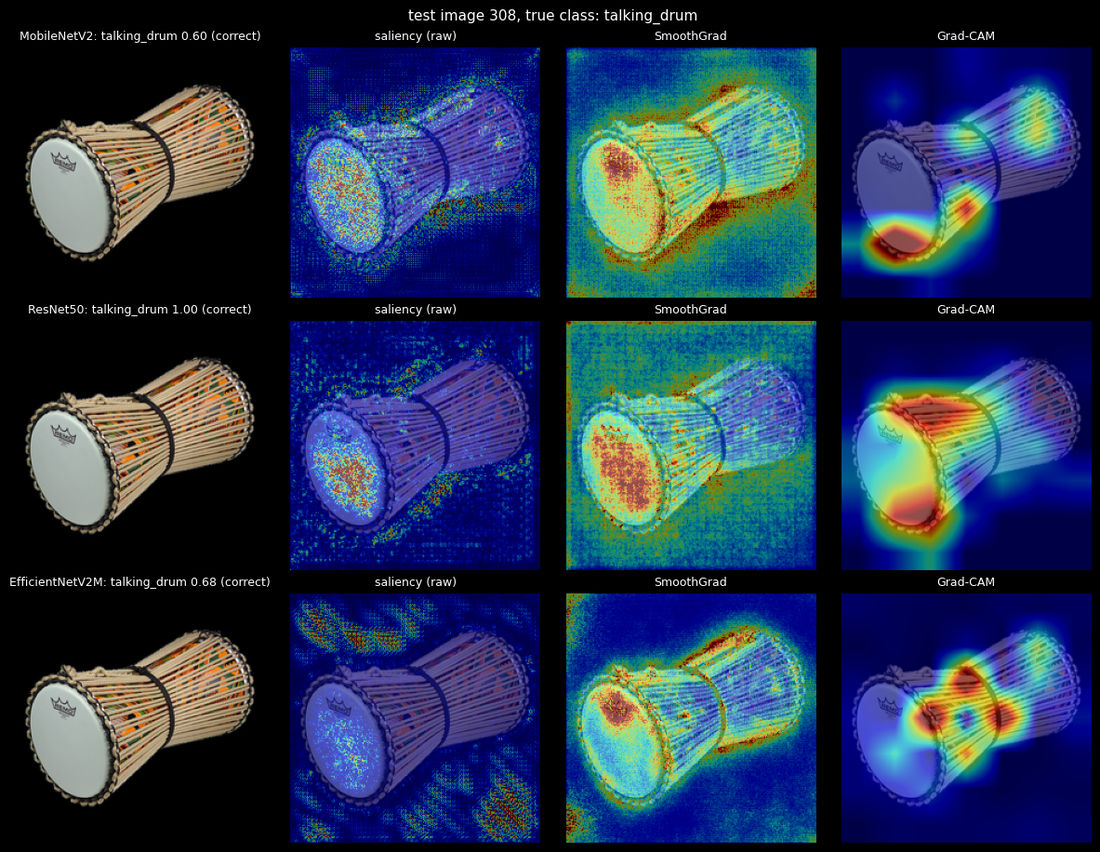

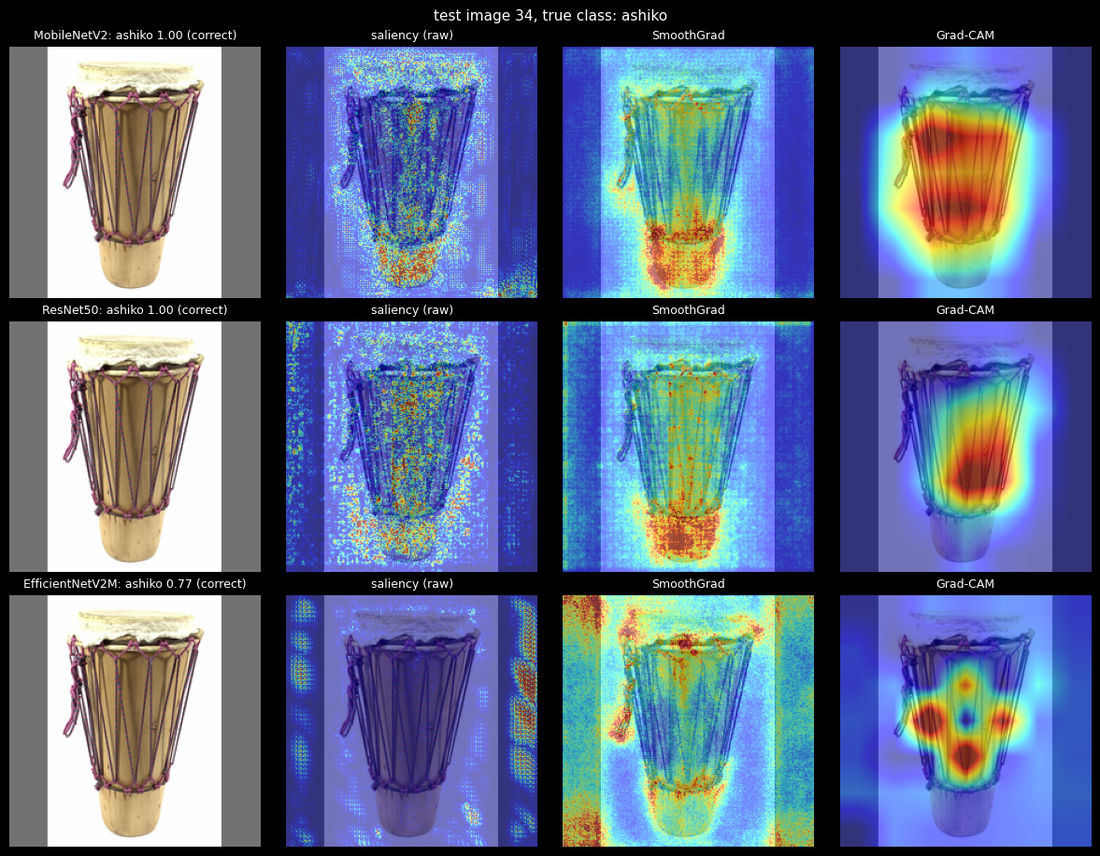

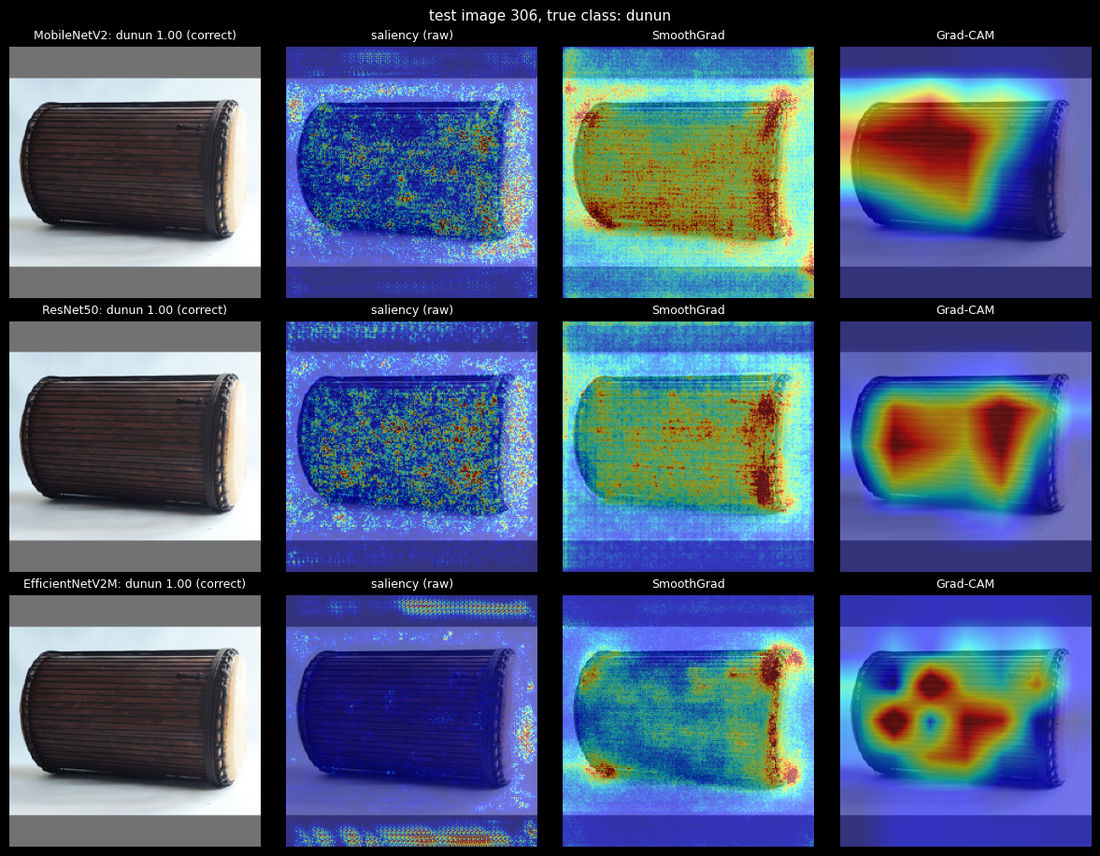

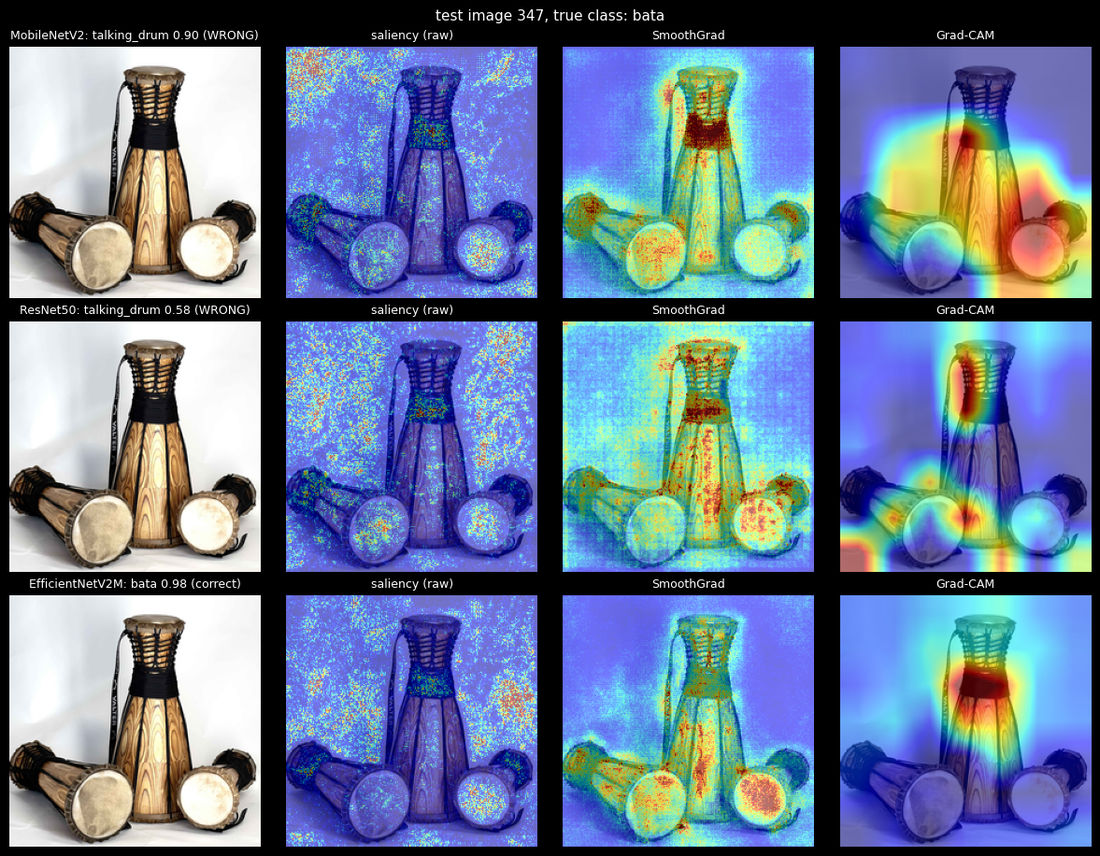

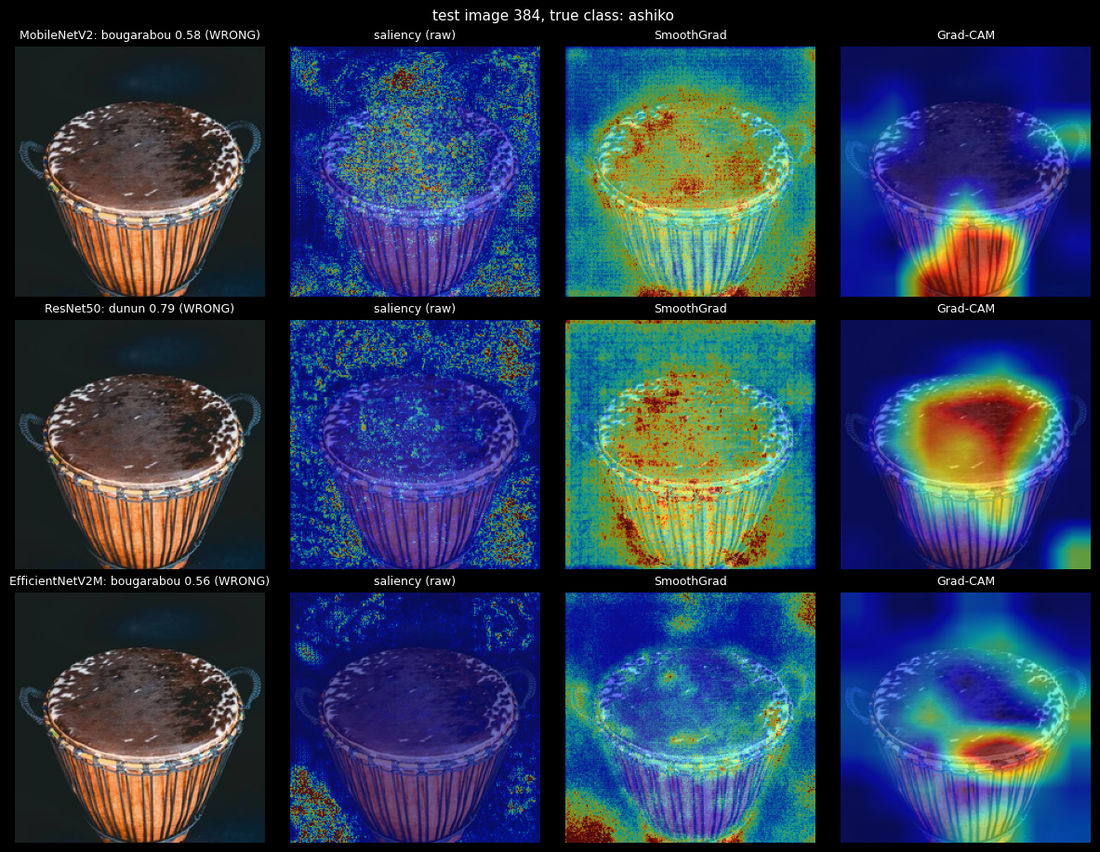

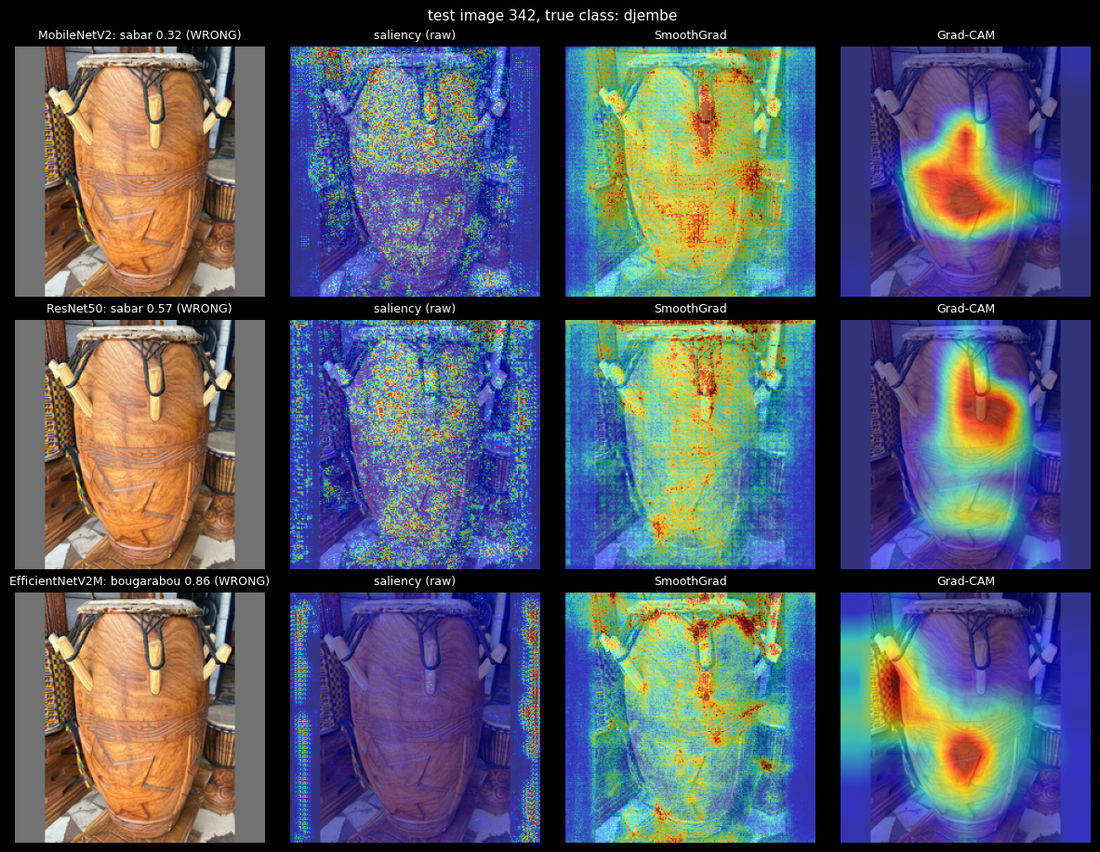

In [9]:
for i in CORRECT_IDX + WRONG_IDX:
    fig, axes = plt.subplots(len(APPLICATIONS), 4, figsize=(12, 3.1 * len(APPLICATIONS)))
    for row, key in zip(axes, APPLICATIONS):
        m = get_maps(key, i)
        verdict = 'correct' if m['pred'] == y_test[i] else 'WRONG'
        row[0].imshow(X_test[i])
        row[0].set_title(f'{NAME[key]}: {class_names[m["pred"]]} {m["probs"][m["pred"]]:.2f} ({verdict})', fontsize=9)
        for ax, (title, heat) in zip(row[1:], [('saliency (raw)', m['raw']), ('SmoothGrad', m['smooth']), ('Grad-CAM', m['cam'])]):
            ax.imshow(xai.overlay(X_test[i], heat))
            ax.set_title(title, fontsize=9)
        for ax in row:
            ax.axis('off')
    fig.suptitle(f'test image {i}, true class: {class_names[y_test[i]]}', fontsize=11)
    plt.tight_layout()
    plt.show()

*TEAM TO COMPLETE AFTER RUNNING — replace this cell with 3–4 sentences.* Across the six figures, does one application consistently put its heat on the drum while another puts it elsewhere, or do they look alike and differ only in their scores? On the mistakes, do the applications err in the same way and for the same reason? Do not claim more than six images show; section 4 has the whole test set.

## 4. The shortcut hunt

A shortcut is a feature that predicts the class in our data without being the drum. Scraped data makes them real, and Notebook 2 flagged our main suspect: **the gray padding**. We padded every photo to a square, so how much padding an image has, and on which sides, is set by its aspect ratio, and aspect ratios differ between classes. A model could learn "gray bars at the sides means `sabar`" instead of learning drums. Other suspects: a plain studio background, a border or watermark, and the website a photo came from.

The plan, from cheapest to most conclusive:

1. **4.1 Where is the padding?** Find the padded pixels in every image and ask whether padding alone predicts the class.
2. **4.2 Where does the attention go?** Compute Grad-CAM for every test image and measure how much lands on the border band and on the padding.
3. **4.3 – 4.5** Look at the average attention per class, per class table and the most border-focused images.
4. **4.6 Image source:** does the model do better on photos from sites it saw before?
5. **4.7 Ablations:** remove regions across the whole test set and re-measure accuracy. A picture suggests; an ablation measures.

### 4.1 Where is the padding?

Notebook 2 padded with one exact gray (114), so a row or column made entirely of that value is padding. `pad_mask` finds them. The table is by class, from the **training** images. The last two columns are the test of the hypothesis: a tiny decision tree sees **only** how much padding each image has on its sides and on its top and bottom, nothing about the drum, and has to guess the class. If it beats guessing by a lot, padding alone carries class information that a model could use.

In [10]:
def pad_mask(img):
    is_pad = (img == PAD_FILL).all(axis=2)
    rows, cols = is_pad.all(axis=1), is_pad.all(axis=0)          # whole rows / columns of padding
    return rows[:, None] | cols[None, :], rows.mean(), cols.mean()


def pad_info(images):
    masks, row_frac, col_frac = zip(*[pad_mask(x) for x in images])
    return np.stack(masks), np.array(row_frac), np.array(col_frac)


pad_train, rows_train, cols_train = pad_info(X_train)
pad_test, rows_test, cols_test = pad_info(X_test)

per_class = pd.DataFrame({
    'mean padded share of image': pd.Series(pad_train.mean(axis=(1, 2))).groupby(y_train).mean(),
    'images with side bars': pd.Series(cols_train > 0.02).groupby(y_train).mean(),
    'images with top/bottom bars': pd.Series(rows_train > 0.02).groupby(y_train).mean(),
}).set_index(pd.Index(class_names)).round(3)

tree = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(np.c_[rows_train, cols_train], y_train)
tree_acc = accuracy_score(y_test, tree.predict(np.c_[rows_test, cols_test]))
chance = np.bincount(y_test).max() / len(y_test)
print(f'Class guessed from padding alone: test accuracy {tree_acc:.3f}. Always guessing the biggest class: {chance:.3f}. Random guessing: {1 / n_classes:.3f}.')
for key in APPLICATIONS:
    print(f'{NAME[key]} from the image: {accuracy_score(y_test, pred[key]):.3f}')
per_class

Class guessed from padding alone: test accuracy 0.250. Always guessing the biggest class: 0.145. Random guessing: 0.125.
MobileNetV2 from the image: 0.760
ResNet50 from the image: 0.790
EfficientNetV2M from the image: 0.760


,mean padded share of image,images with side bars,images with top/bottom bars
ashiko,0.210,0.520,0.213
bata,0.234,0.517,0.337
bendir,0.169,0.294,0.355
bougarabou,0.219,0.351,0.298
djembe,0.210,0.376,0.277
dunun,0.221,0.137,0.624
sabar,0.256,0.259,0.568
talking_drum,0.194,0.335,0.382


### 4.2 Where does Grad-CAM put its attention, over the whole test set?

Grad-CAM is one backward pass, so we can afford it for **every** test image and every application. For each map (the predicted class, as the app would show it) we record:

- the **share of attention on the border band** (the outer 28 pixels all round), which is where watermarks, frames, studio edges and padding live; the band covers 44% of the image, so uniform attention would put 44% there
- the **share of attention on padded pixels**, to compare with the share of the image that is padding
- the **top 20% of the map** as a mask, kept for the ablation in 4.7
- a running sum of the maps per true class, for the mean attention picture in 4.3

A ratio above 1 means the model puts more attention there than the area alone would give it. The drum is not always in the middle, so a ratio below 1 on the border is expected and a high one is the alarm.

In [11]:
BORDER = np.ones((IMG_SIZE, IMG_SIZE), dtype=bool)
BORDER[BAND:-BAND, BAND:-BAND] = False
BORDER_AREA = BORDER.mean()

diag, class_cam = {}, {}
for key in APPLICATIONS:
    start = time.perf_counter()
    n = len(X_test)
    border_share, pad_share, top_mask = np.zeros(n), np.zeros(n), np.zeros((n, IMG_SIZE, IMG_SIZE), dtype=bool)
    cam_sum, cam_n = np.zeros((n_classes, IMG_SIZE, IMG_SIZE), dtype='float32'), np.zeros(n_classes)
    for i in range(n):
        heat = np.maximum(xai.grad_cam(joined[key], X_test[i]), 0)
        total = heat.sum() + 1e-8
        border_share[i] = heat[BORDER].sum() / total
        pad_share[i] = heat[pad_test[i]].sum() / total
        top_mask[i] = (heat >= np.quantile(heat, 1 - ABLATE_FRAC)) & (heat > 0)
        cam_sum[y_test[i]] += xai.norm(heat)
        cam_n[y_test[i]] += 1
    diag[key] = dict(border=border_share, pad=pad_share, top=top_mask)
    class_cam[key] = cam_sum / np.maximum(cam_n, 1)[:, None, None]
    print(f'{NAME[key]}: Grad-CAM for {n} images in {time.perf_counter() - start:.0f} s')

summary = pd.DataFrame({NAME[key]: {
    'attention on border band': diag[key]['border'].mean(),
    'border band share of image': BORDER_AREA,
    'border ratio (attention / area)': diag[key]['border'].mean() / BORDER_AREA,
    'attention on padding': diag[key]['pad'].mean(),
    'padding share of image': pad_test.mean(),
    'padding ratio (attention / area)': diag[key]['pad'].mean() / max(pad_test.mean(), 1e-8),
} for key in APPLICATIONS}).T
summary.round(3)

MobileNetV2: Grad-CAM for 420 images in 142 s
ResNet50: Grad-CAM for 420 images in 280 s
EfficientNetV2M: Grad-CAM for 420 images in 911 s


,attention on border band,border band share of image,border ratio (attention / area),attention on padding,padding share of image,padding ratio (attention / area)
MobileNetV2,0.188,0.438,0.430,0.071,0.228,0.312
ResNet50,0.199,0.438,0.455,0.055,0.228,0.243
EfficientNetV2M,0.280,0.438,0.641,0.136,0.228,0.599


### 4.3 Where each class's evidence sits

Per class: the **mean training image** on the top row and the **mean Grad-CAM map** of the class's test images, laid over it, on the bottom. If a class's evidence concentrates in the same place on every image, that place is what the model has learned for the class. A bright border, bright side strips or a bright corner where the mean image shows no drum is the shortcut signature. One figure per application.

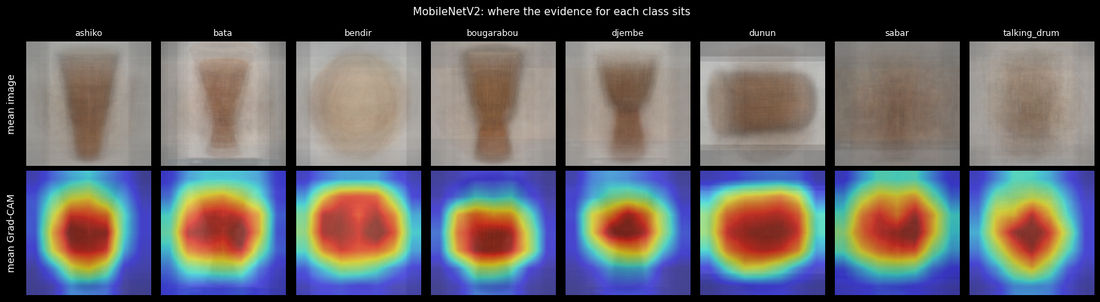

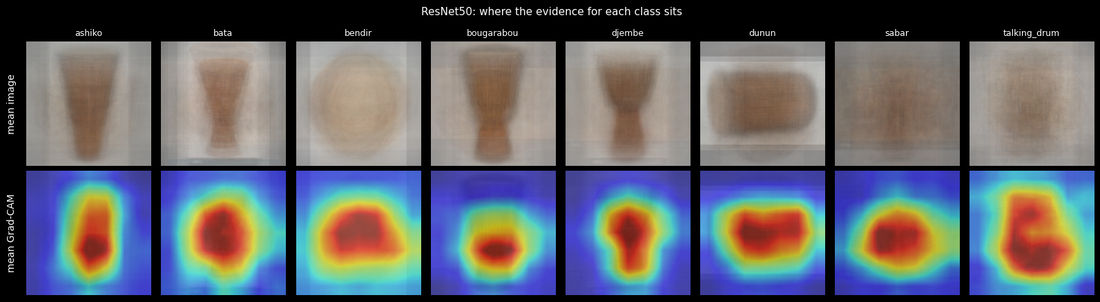

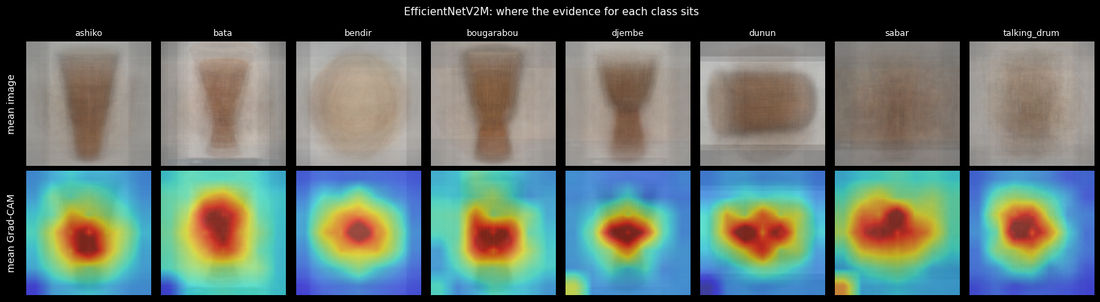

In [12]:
mean_img = {c: X_train[y_train == c].mean(axis=0).astype('uint8') for c in range(n_classes)}
for key in APPLICATIONS:
    fig, axes = plt.subplots(2, n_classes, figsize=(2.0 * n_classes, 4.5))
    for c in range(n_classes):
        axes[0, c].imshow(mean_img[c]); axes[0, c].set_title(class_names[c], fontsize=9)
        axes[1, c].imshow(xai.overlay(mean_img[c], class_cam[key][c]))
        axes[0, c].axis('off'); axes[1, c].axis('off')
    axes[0, 0].text(-0.08, 0.5, 'mean image', transform=axes[0, 0].transAxes, rotation=90, va='center', ha='right')
    axes[1, 0].text(-0.08, 0.5, 'mean Grad-CAM', transform=axes[1, 0].transAxes, rotation=90, va='center', ha='right')
    fig.suptitle(f'{NAME[key]}: where the evidence for each class sits', fontsize=11)
    plt.tight_layout()
    plt.show()

### 4.4 Border attention by class

The same border measure, split by true class: attention on the border band divided by the band's share of the image. Anything well above 1 means that class's predictions lean on the edge of the picture.

In [13]:
border_by_class = pd.DataFrame({NAME[key]: pd.Series(diag[key]['border']).groupby(y_test).mean() / BORDER_AREA for key in APPLICATIONS})
border_by_class.index = class_names
border_by_class.round(2)

,MobileNetV2,ResNet50,EfficientNetV2M
ashiko,0.39,0.40,0.63
bata,0.48,0.51,0.70
bendir,0.45,0.59,0.53
bougarabou,0.32,0.43,0.70
djembe,0.35,0.34,0.71
dunun,0.46,0.38,0.60
sabar,0.53,0.47,0.73
talking_drum,0.46,0.57,0.49


### 4.5 The images with the most border-focused attention

For the primary model, the **correctly classified** images whose Grad-CAM puts the most attention on the border band. These are the likeliest places to find a watermark, a text overlay, a frame or a background cue that did the work. Each is titled with its class and the web page it came from. Look at them, then decide whether what the heat sits on is the drum.

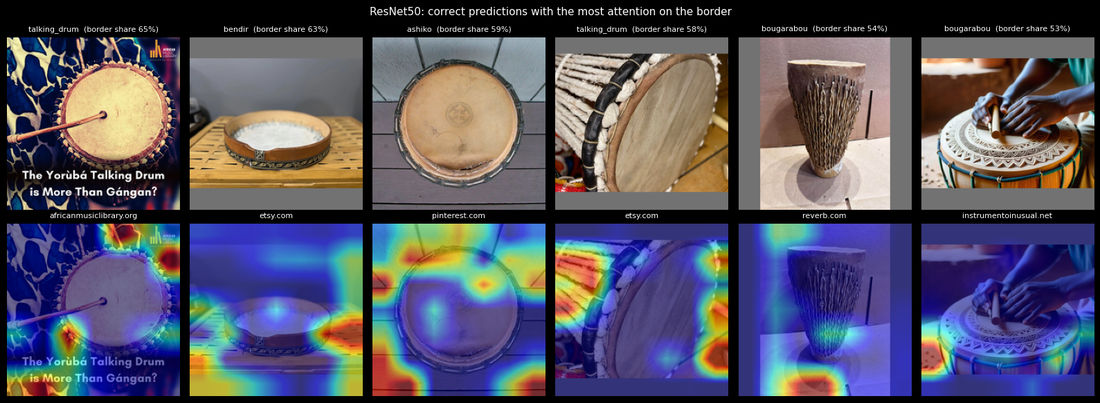

In [14]:
ok = np.where(pred[PRIMARY] == y_test)[0]
top_border = ok[np.argsort(-diag[PRIMARY]['border'][ok])[:6]]

fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for col, i in enumerate(top_border):
    cam = get_maps(PRIMARY, i)['cam']
    axes[0, col].imshow(X_test[i]); axes[0, col].set_title(f'{class_names[y_test[i]]}  (border share {diag[PRIMARY]["border"][i]:.0%})', fontsize=8)
    axes[1, col].imshow(xai.overlay(X_test[i], cam)); axes[1, col].set_title(test_rows.loc[i, 'domain'][:28], fontsize=8)
    axes[0, col].axis('off'); axes[1, col].axis('off')
fig.suptitle(f'{NAME[PRIMARY]}: correct predictions with the most attention on the border', fontsize=11)
plt.tight_layout()
plt.show()

*TEAM TO COMPLETE AFTER RUNNING — replace this cell with 3–4 sentences.* What does the heat sit on in these six: padding bars, a frame, text, a watermark, part of the drum that happens to be near the edge, or a background (a wall, grass, a studio sweep)? Does the mean Grad-CAM in 4.3 show the same thing for a whole class? Do the classes with a high border ratio in 4.4 match the classes with the most padding in 4.1?

### 4.6 Does the image source matter?

Scraped photos arrive in clusters: a shop or a school photographs many drums the same way, with the same table, wall and lighting. If a class's training photos come mostly from one website, the model can learn that website's look, and a test photo from the same site is easier than one from anywhere else. Two measures:

- how concentrated each class's **training** images are in a few websites
- test accuracy on images whose website **also supplies training images of the same class** against images from a website the model never saw for that class

A big gap means part of the accuracy is "I know this studio", not "I know this drum". It is a hint, not proof: photos from a known site may also just be better photos.

In [15]:
by_class = []
for c, name in enumerate(class_names):
    d = train_rows.loc[train_rows['label'] == name, 'domain']
    d = d[d != 'unknown']
    top = d.value_counts()
    by_class.append({'class': name, 'training images with a known source': len(d), 'different websites': d.nunique(),
                     'most common website': top.index[0] if len(top) else '-', 'its share of the class': round(top.iloc[0] / max(len(d), 1), 3) if len(top) else 0})
display(pd.DataFrame(by_class).set_index('class'))

seen = set(zip(train_rows['label'], train_rows['domain'])) - {(l, 'unknown') for l in class_names}
known_site = np.array([(l, d) in seen for l, d in zip(test_rows['label'], test_rows['domain'])])
gap = pd.DataFrame({NAME[key]: {
    'accuracy, site also in training for this class': accuracy_score(y_test[known_site], pred[key][known_site]) if known_site.any() else np.nan,
    'accuracy, site not seen for this class': accuracy_score(y_test[~known_site], pred[key][~known_site]) if (~known_site).any() else np.nan,
} for key in APPLICATIONS}).T
print(f'{known_site.sum()} test images come from a website that also supplies training images of the same class; {(~known_site).sum()} do not.')
gap.round(3)

,training images with a known source,different websites,most common website,its share of the class
class,,,,
ashiko,225,63,pinterest.com,0.133
bata,172,65,alamy.com,0.116
bendir,214,68,etsy.com,0.196
bougarabou,188,80,africandrumming.com.au,0.096
djembe,242,79,dreamstime.com,0.112
dunun,226,64,african-percussion.net,0.372
sabar,243,97,youtube.com,0.177
talking_drum,170,73,ar.inspiredpencil.com,0.135


323 test images come from a website that also supplies training images of the same class; 97 do not.


,"accuracy, site also in training for this class","accuracy, site not seen for this class"
MobileNetV2,0.793,0.649
ResNet50,0.827,0.670
EfficientNetV2M,0.802,0.619


### 4.7 Ablations: measuring what the maps only suggest

Each ablation **greys out a region of every test image** (with the same gray 114 the padding uses, so the model sees a plain neutral patch and not black) and re-measures accuracy. The chance level is 1/8 = 12.5%.

| Ablation | What it asks | If the model reads the drum |
|---|---|---|
| **Border greyed** (outer 28 px) | Does it need the edge of the picture? | Accuracy barely moves |
| **Centre greyed** (only the border kept) | Can it name the drum **without seeing the middle**? | Accuracy collapses toward chance |
| **Grad-CAM region greyed** (its own top 20%) | Do its own maps point at what it depends on? | Accuracy falls sharply |
| **Random square greyed** (same 20% area) | The control: how much does losing *any* 20% cost? | Falls much less than the Grad-CAM region |

The last two work as a pair: removing the region Grad-CAM points at should cost far more than removing a random region of the same size, or the map was not pointing at what the model uses. The centre-greyed test is the sharpest shortcut test: a drum photo has some honest context (a hand, a stand), but accuracy far above chance with the drum hidden means the model is reading something else.

In [16]:
side = int(round(np.sqrt(ABLATE_FRAC) * IMG_SIZE))              # a square covering ABLATE_FRAC of the image
abl_rng = np.random.default_rng(SEED)
corners = abl_rng.integers(0, IMG_SIZE - side + 1, size=(len(X_test), 2))
random_square = np.zeros((len(X_test), IMG_SIZE, IMG_SIZE), dtype=bool)
for i, (r, c) in enumerate(corners):
    random_square[i, r:r + side, c:c + side] = True


def greyed(images, masks):
    out = images.copy()
    out[masks] = PAD_FILL                    # masks: (n, h, w) boolean or (h, w) broadcast over the batch
    return out


rows = {}
for key in APPLICATIONS:
    baseline = accuracy_score(y_test, pred[key])
    scores = {
        'none (baseline)': baseline,
        f'border greyed (outer {BAND} px)': accuracy_score(y_test, predict_probs(key, greyed(X_test, np.broadcast_to(BORDER, X_test.shape[:3]))).argmax(axis=1)),
        'centre greyed (only the border kept)': accuracy_score(y_test, predict_probs(key, greyed(X_test, np.broadcast_to(~BORDER, X_test.shape[:3]))).argmax(axis=1)),
        f"Grad-CAM's own top {ABLATE_FRAC:.0%} greyed": accuracy_score(y_test, predict_probs(key, greyed(X_test, diag[key]['top'])).argmax(axis=1)),
        f'random {side}x{side} square greyed (same area)': accuracy_score(y_test, predict_probs(key, greyed(X_test, random_square)).argmax(axis=1)),
    }
    rows[NAME[key]] = scores

ablation = pd.DataFrame(rows).T
print(f'chance level {1 / n_classes:.3f}; always guessing the biggest class {chance:.3f}')
ablation.round(3)

chance level 0.125; always guessing the biggest class 0.145


,none (baseline),border greyed (outer 28 px),centre greyed (only the border kept),Grad-CAM's own top 20% greyed,random 100x100 square greyed (same area)
MobileNetV2,0.76,0.712,0.198,0.393,0.593
ResNet50,0.79,0.748,0.202,0.379,0.674
EfficientNetV2M,0.76,0.724,0.340,0.507,0.695


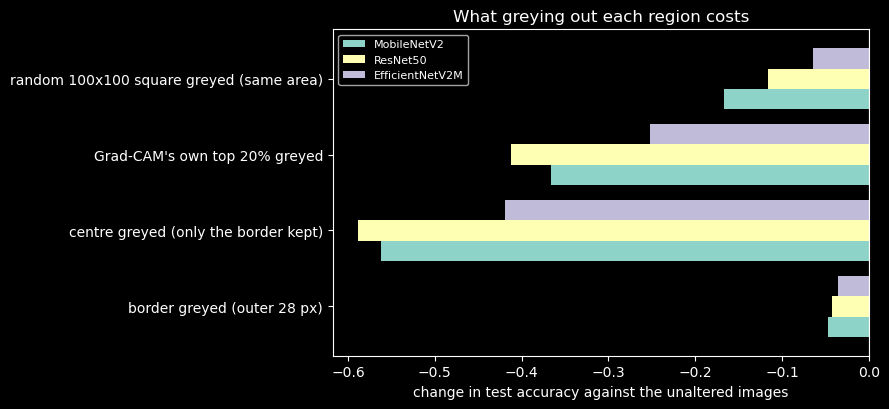

In [17]:
drop = ablation.sub(ablation['none (baseline)'], axis=0).drop(columns='none (baseline)')
ax = drop.T.plot.barh(figsize=(9, 4.2), width=0.8)
ax.axvline(0, color='white', linewidth=0.8)
ax.set_xlabel('change in test accuracy against the unaltered images')
ax.set_title('What greying out each region costs')
ax.legend(title=None, fontsize=8)
plt.tight_layout()
plt.show()

*TEAM TO COMPLETE AFTER RUNNING — replace this cell with a short, honest verdict (5–8 sentences) on whether we found a shortcut.* Use the numbers above, not the pictures alone.

- **Padding (4.1, 4.2):** how well did padding alone predict the class, compared with guessing? Does Grad-CAM put more or less attention on padding than its share of the image?
- **Border and background (4.2–4.5, centre greyed):** how far above 12.5% chance did accuracy stay with the drum hidden, for each application? Is that honest context or a cue?
- **Do the maps point at what the models use?** Compare the cost of greying the Grad-CAM region with the random square of the same area.
- **Source (4.6):** is there a gap between known and unseen websites?
- **If you found a shortcut:** state it, quote the accuracy change from the ablation, and say which class it affects. **If you did not:** say so and name the evidence that convinced you. A clean result honestly shown is worth full marks.

## 5. Do the two methods agree?

Saliency and Grad-CAM answer related but different questions, so where they disagree is itself a diagnosis (`U2-2_CNN-8_Explainability` §4.4). We measure agreement on a stratified sample of **three test images per class** (24 images) for each application: take the top 20% of each map and compute the **overlap (intersection over union)** between each pair. 1 means the same region, 0 means no shared pixels; two random 20% regions would overlap about 0.11. `roughness` repeats the raw-against-SmoothGrad comparison from section 2.

In [18]:
TOP = 0.20


def top_region(heat, frac=TOP):
    return heat >= np.quantile(heat, 1 - frac)


def iou(a, b):
    return (a & b).sum() / ((a | b).sum() + 1e-8)


sample_rng = np.random.default_rng(SEED)
sample = np.concatenate([sample_rng.choice(np.where(y_test == c)[0], size=min(3, int((y_test == c).sum())), replace=False) for c in range(n_classes)])

rows = []
for key in APPLICATIONS:
    start = time.perf_counter()
    for i in sample:
        m = get_maps(key, int(i))
        r, s, c = (top_region(m[k]) for k in ('raw', 'smooth', 'cam'))
        rows.append({'application': NAME[key], 'test index': int(i), 'correct': bool(m['pred'] == y_test[i]),
                     'raw vs SmoothGrad': iou(r, s), 'SmoothGrad vs Grad-CAM': iou(s, c), 'raw vs Grad-CAM': iou(r, c),
                     'roughness raw': roughness(m['raw']), 'roughness SmoothGrad': roughness(m['smooth'])})
    print(f'{NAME[key]}: {len(sample)} images in {time.perf_counter() - start:.0f} s')

agreement = pd.DataFrame(rows)
agreement.groupby('application', sort=False).mean(numeric_only=True).drop(columns='test index').round(3)

MobileNetV2: 24 images in 101 s
ResNet50: 24 images in 249 s
EfficientNetV2M: 24 images in 696 s


,correct,raw vs SmoothGrad,SmoothGrad vs Grad-CAM,raw vs Grad-CAM,roughness raw,roughness SmoothGrad
application,,,,,,
MobileNetV2,0.708,0.256,0.234,0.169,1.199,0.343
ResNet50,0.625,0.250,0.268,0.171,1.094,0.317
EfficientNetV2M,0.625,0.108,0.176,0.058,1.298,0.373


                          mean  count
application     correct              
MobileNetV2     True     0.231     17
                False    0.242      7
ResNet50        True     0.265     15
                False    0.273      9
EfficientNetV2M True     0.181     15
                False    0.169      9


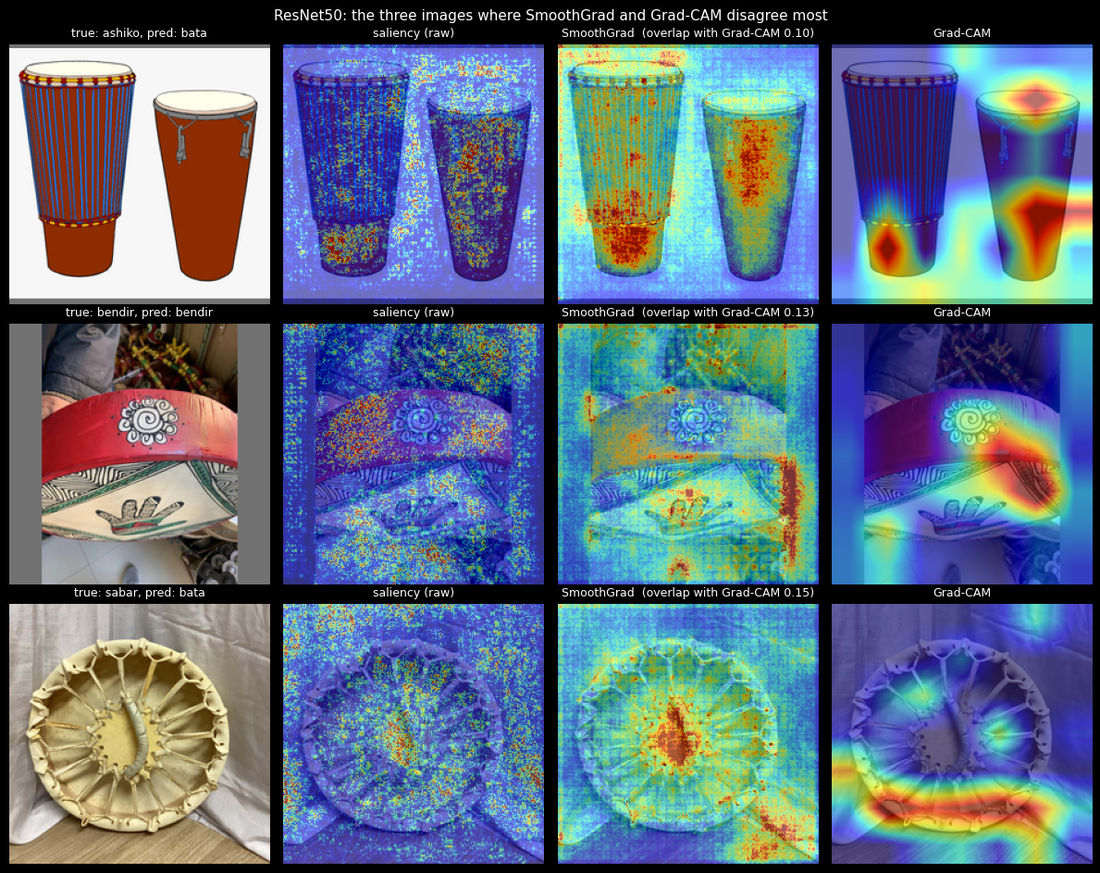

In [19]:
# Agreement on correct against misclassified images, and the images where SmoothGrad and Grad-CAM disagree most
print(agreement.groupby(['application', 'correct'], sort=False)['SmoothGrad vs Grad-CAM'].agg(['mean', 'count']).round(3).to_string())

worst = agreement[agreement['application'] == NAME[PRIMARY]].nsmallest(3, 'SmoothGrad vs Grad-CAM')
fig, axes = plt.subplots(len(worst), 4, figsize=(12, 3.2 * len(worst)))
for row, (_, r) in zip(np.atleast_2d(axes), worst.iterrows()):
    i = int(r['test index']); m = get_maps(PRIMARY, i)
    row[0].imshow(X_test[i]); row[0].set_title(f'true: {class_names[y_test[i]]}, pred: {class_names[m["pred"]]}', fontsize=9)
    for ax, (title, heat) in zip(row[1:], [('saliency (raw)', m['raw']), ('SmoothGrad', m['smooth']), ('Grad-CAM', m['cam'])]):
        ax.imshow(xai.overlay(X_test[i], heat)); ax.set_title(title + (f'  (overlap with Grad-CAM {r["SmoothGrad vs Grad-CAM"]:.2f})' if title == 'SmoothGrad' else ''), fontsize=9)
    for ax in row:
        ax.axis('off')
fig.suptitle(f'{NAME[PRIMARY]}: the three images where SmoothGrad and Grad-CAM disagree most', fontsize=11)
plt.tight_layout()
plt.show()

*TEAM TO COMPLETE AFTER RUNNING — replace this cell with 3–5 sentences.* Do the two methods agree on average, and is that the same for all three applications? Do they agree less on misclassified images? Look at the three images where they disagree most: is SmoothGrad on a detail (a rim, a pattern, text) while Grad-CAM sits on the whole drum, or the reverse? Disagreement can mean the evidence is spread out, that the model is unsure, or that one method is picking up something the other cannot resolve, such as a thin watermark that a 7 × 7 grid smears away.

## 6. Discussion

*TEAM TO COMPLETE AFTER RUNNING — replace this cell with a short discussion (a paragraph or two) answering both questions with evidence from this notebook, not general principles.*

**Would we deploy this model?** Use the test accuracy from 1.3, the weak classes from Notebook 3, the shortcut verdict from 4.7 and the mistakes from 3.3. Would a drum photographed somewhere new (a different background, no padding, a different angle) behave like our test photos? The two stress tests in the Streamlit app, a photo of something that is not a drum and a deliberately hard one, are the practical check.

**What would we fix first, and why that one?** Choose from: more data (which class, from where), different classes (is there a pair the models cannot separate, or a label that is wrong), better cleaning (a watermark, a frame, mislabeled test images found in 3.3), a different Keras application (did the size comparison in Notebook 3 or the localization in 3.4 give a reason to), or a change to the padding. Name the single change you expect to help most.

---

## Review

This notebook opened up the three Keras applications of Notebook 3 on our drum test set:

1. **The models** were rebuilt exactly as in Notebook 3, joined to their probes from `models/`, and **checked**: accuracy and macro-F1 reproduce Notebook 3's, and the module's predictions match plain Keras.
2. **The methods** were raw saliency, SmoothGrad (32 noisy copies) and Grad-CAM, from the provided `image_explainers.py`, which we read before using. All three applications end in a 7 × 7 feature grid, so Grad-CAM is coarse for each.
3. **The images** were a seeded random draw: three correct images from three classes, three mistakes, and each image through all three applications, including the evidence for the **true** class on the mistakes.
4. **The shortcut hunt** tested padding, the border band, per-class attention and the image source, then **measured** the result with ablations: border greyed, centre greyed, Grad-CAM's own region against a random region of the same size.
5. **The two methods** were compared by the overlap of their top-20% regions over 24 images per application.

**Next:** `P2_Images-5_App.py` puts all three models behind a Streamlit page that classifies an uploaded drum photo and draws these same maps, with the exact preprocessing from Notebook 2.